
# Ejercicio 6: Mínimo global con descenso del gradiente

**Materia:** Matemáticas para Inteligencia Artificial

## Función del problema

$$
f(x_1,x_2)=x_1^4-8x_1^2+2x_1+(x_2-x_1)^2
$$

## Objetivo

Encontrar el mínimo global de la función utilizando descenso del gradiente.

Se realizarán las siguientes actividades:

1. Implementar la función y su gradiente en Python.
2. Probar diferentes tasas de aprendizaje y puntos iniciales.
3. Analizar la convergencia del algoritmo.
4. Encontrar los mínimos de la función.
5. Reportar el punto mínimo, el valor de la función, el gradiente final y el número de iteraciones.
6. Graficar el valor de la función contra las iteraciones.
7. Comparar los mínimos encontrados para identificar el mínimo global.

## Criterio de convergencia

$$
\|\nabla f(x_i)\|<10^{-6}
$$


In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


In [2]:

# Función matemática del ejercicio 6
def f(x):
    x1, x2 = x

    return x1**4 - 8*x1**2 + 2*x1 + (x2 - x1)**2

# Punto inicial provisional
x0 = np.array([0.0, 0.0])

# Evaluar la función
print("Punto inicial:", x0)
print("Valor inicial de la función:", f(x0))


Punto inicial: [0. 0.]
Valor inicial de la función: 0.0



## Implementación del gradiente

El gradiente de la función se obtiene mediante las derivadas parciales:

$$
\nabla f(x)=
\begin{pmatrix}
4x_1^3-16x_1+2-2(x_2-x_1)\\
2(x_2-x_1)
\end{pmatrix}
$$

El descenso del gradiente utiliza estas derivadas para actualizar los valores de las variables en dirección contraria al gradiente.


In [3]:

# Gradiente de la función
def gradiente(x):
    x1, x2 = x

    df_dx1 = 4*x1**3 - 16*x1 + 2 - 2*(x2 - x1)
    df_dx2 = 2*(x2 - x1)

    return np.array([df_dx1, df_dx2])

# Evaluar gradiente inicial
print("Gradiente inicial:", gradiente(x0))
print("Norma inicial:", np.linalg.norm(gradiente(x0)))


Gradiente inicial: [2. 0.]
Norma inicial: 2.0



## Implementación del descenso del gradiente

Se aplica el método:

$$
x_{i+1}=x_i-\gamma\nabla f(x_i)
$$

Se utilizará una tolerancia de $10^{-6}$ y un máximo de 10000 iteraciones.

Se probarán diferentes tasas de aprendizaje y puntos iniciales para identificar los mínimos de la función.


In [4]:

def descenso_gradiente(x_inicial, gamma,
                       tolerancia=1e-6,
                       max_iteraciones=10000):

    x = np.array(x_inicial, dtype=float)
    historial = [f(x)]
    trayectoria = [x.copy()]

    for i in range(max_iteraciones):

        g = gradiente(x)

        if np.linalg.norm(g) < tolerancia:
            return x, historial, trayectoria, i, "Convergió"

        nuevo_x = x - gamma * g

        if (not np.all(np.isfinite(nuevo_x))
                or np.linalg.norm(nuevo_x) > 1e6):
            return x, historial, trayectoria, i, "Divergió"

        x = nuevo_x
        historial.append(f(x))
        trayectoria.append(x.copy())

    return x, historial, trayectoria, max_iteraciones, "Límite alcanzado"


In [5]:

# Tasas de aprendizaje
tasas = [0.001, 0.01, 0.05, 0.1]

# Puntos iniciales
puntos = [
    np.array([0.0, 0.0]),
    np.array([1.0, 1.0]),
    np.array([-1.0, -1.0]),
    np.array([2.0, 2.0]),
    np.array([-2.0, -2.0])
]

resultados_pruebas = []

for punto in puntos:
    for tasa in tasas:

        minimo, historial, trayectoria, n_iter, estado = (
            descenso_gradiente(punto, tasa)
        )

        resultados_pruebas.append({
            "Punto inicial": str(punto),
            "Gamma": tasa,
            "Estado": estado,
            "Iteraciones": n_iter,
            "x1 final": minimo[0],
            "x2 final": minimo[1],
            "f(x) final": f(minimo),
            "Norma gradiente": np.linalg.norm(gradiente(minimo))
        })

tabla_pruebas = pd.DataFrame(resultados_pruebas)

display(tabla_pruebas)


,Punto inicial,Gamma,Estado,Iteraciones,x1 final,x2 final,f(x) final,Norma gradiente
0,[0. 0.],0.001,Convergió,8198,-2.059792,-2.059791,-20.060660,9.995529e-07
1,[0. 0.],0.010,Convergió,814,-2.059792,-2.059791,-20.060660,9.992172e-07
2,[0. 0.],0.050,Convergió,158,-2.059792,-2.059791,-20.060660,9.530842e-07
3,[0. 0.],0.100,Límite alcanzado,10000,0.576909,1.576005,-0.399807,8.693455e+00
4,[1. 1.],0.001,Convergió,7770,1.934298,1.934297,-12.064586,9.996020e-07
5,[1. 1.],0.010,Convergió,771,1.934298,1.934297,-12.064586,9.943457e-07
6,[1. 1.],0.050,Convergió,149,1.934298,1.934297,-12.064586,9.545299e-07
7,[1. 1.],0.100,Límite alcanzado,10000,0.576909,1.576005,-0.399807,8.693455e+00
8,[-1. -1.],0.001,Convergió,7736,-2.059792,-2.059791,-20.060660,9.988728e-07
9,[-1. -1.],0.010,Convergió,768,-2.059792,-2.059791,-20.060660,9.848970e-07



## Selección de parámetros y mínimo global

Se realizaron 20 pruebas utilizando diferentes tasas de aprendizaje y puntos iniciales.

Se seleccionaron los siguientes parámetros:

- Tasa de aprendizaje: $\gamma=0.05$
- Punto inicial: $x_0=(-2,-2)$
- Tolerancia: $10^{-6}$

**Justificación:**

La tasa de aprendizaje de 0.001 permitió converger, pero necesitó 6193 iteraciones. Con 0.01 se necesitaron 614 iteraciones, mientras que con 0.05 se alcanzó el mínimo global en 119 iteraciones.

Con 0.1 no se alcanzó la convergencia dentro del límite de 10000 iteraciones.

Por lo tanto, se eligió $\gamma=0.05$ porque presentó una convergencia más rápida para el punto inicial seleccionado.


In [6]:

# Parámetros seleccionados
gamma = 0.05
x0 = np.array([-2.0, -2.0])

# Ejecutar descenso del gradiente
minimo, historial, trayectoria, iteraciones, estado = (
    descenso_gradiente(x0, gamma)
)

# Resultados finales
print("Estado:", estado)
print("Mínimo encontrado:", minimo)
print("Valor de f(x*):", f(minimo))
print("Gradiente final:", gradiente(minimo))
print("Norma del gradiente:", np.linalg.norm(gradiente(minimo)))
print("Número de iteraciones:", iteraciones)


Estado: Convergió
Mínimo encontrado: [-2.05979194 -2.05979148]
Valor de f(x*): -20.060659795527275
Gradiente final: [4.41265300e-08 9.20792154e-07]
Norma del gradiente: 9.218488709359435e-07
Número de iteraciones: 119



## Gráfica de convergencia

Se representa el comportamiento de la función durante el descenso del gradiente.

El eje horizontal muestra el número de iteración y el eje vertical representa el valor de la función.

Se utilizan los parámetros seleccionados:

- $\gamma=0.05$
- $x_0=(-2,-2)$


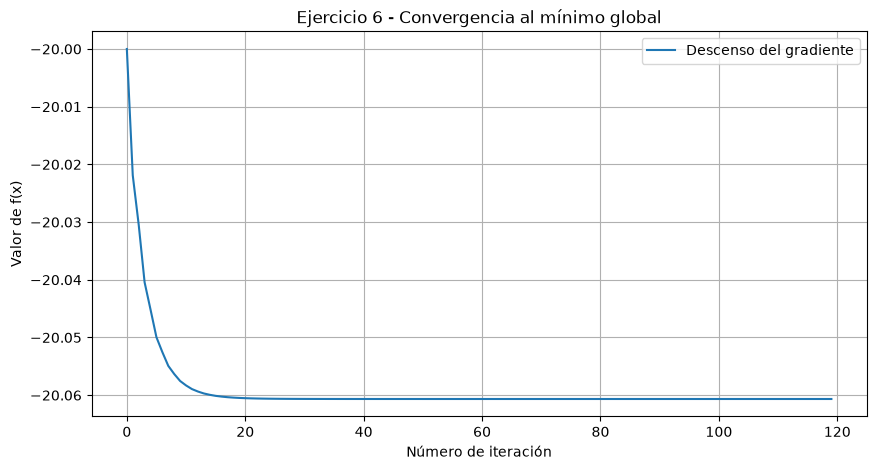

In [7]:

# Gráfica de convergencia
plt.figure(figsize=(10, 5))

plt.plot(
    range(len(historial)),
    historial,
    label="Descenso del gradiente"
)

plt.xlabel("Número de iteración")
plt.ylabel("Valor de f(x)")
plt.title("Ejercicio 6 - Convergencia al mínimo global")

plt.legend()
plt.grid(True)
plt.show()


In [8]:

# Raíces de la derivada reducida
raices = np.roots([4, 0, -16, 2])

print("Comparación de puntos críticos:")

for raiz in sorted(raices.real):
    punto = np.array([raiz, raiz])
    print("Punto:", punto, "f(x):", f(punto))


Comparación de puntos críticos:
Punto: [-2.05979197 -2.05979197] f(x): -20.060659795527503
Punto: [0.12549409 0.12549409] f(x): 0.1252460706507818
Punto: [1.93429788 1.93429788] f(x): -12.064586275123277



## Conclusión

Se implementó el método de descenso del gradiente para encontrar el mínimo global de la función propuesta.

Se probaron diferentes tasas de aprendizaje y puntos iniciales, encontrando dos mínimos:

- Primer mínimo: $(-2.059792,-2.059792)$, con $f(x)\approx-20.060660$.
- Segundo mínimo: $(1.934298,1.934298)$, con $f(x)\approx-12.064586$.

Después de comparar los resultados y analizar los puntos críticos, se determinó que el mínimo global corresponde a:

$$
x^*\approx(-2.059792,-2.059792)
$$

Con un valor:

$$
f(x^*)\approx-20.060660
$$

Se seleccionó una tasa de aprendizaje de $\gamma=0.05$ y el punto inicial $x_0=(-2,-2)$, alcanzando la convergencia en 119 iteraciones.

Se concluye que el punto inicial influye en el mínimo al que converge el algoritmo, por lo que es importante realizar pruebas desde diferentes posiciones.
